# Histórica: una o dos trayectorias conservando el factor de actividad

Comparación nueva e independiente, sin recalibración. **A diferencia del diagnóstico 05, aquí se conserva también el factor de actividad en los dos casos de trayectoria única.** No se modifica el diagnóstico anterior ni ningún módulo/configuración.

Química theta_nv2; parámetros de gas del ajuste histórico `train_019_021`. LAB019–021: calibración previa de esos parámetros. LAB016–018: holdout sin reajuste. Se mantienen iniciales, nutriciones, tiempos y temperaturas del comparador histórico.

## Único cambio: uso de trayectorias

Definimos $a(t)=1+(g_N-1)r(t)$, con gN=`pulse_activity_gain`=0.25 y la misma rampa histórica r. Este factor es exactamente el que ya contiene la formulación original; no es un parámetro nuevo. qN y q0 proceden de la química con/sin nutrición, respectivamente.

En los tres casos:
\[
q_{prod}=\mathrm{gate}\ f_{O2}\ M\ B.
\]

| Caso | B |
|---|---|
| Histórica actual, dos trayectorias | $\max\{a(t)q_0+r(t)(q_N-q_0),0\}$ |
| Sólo trayectoria con nutrición | $\max\{a(t)q_N,0\}$ |
| Sólo trayectoria sin nutrición | $\max\{a(t)q_0,0\}$ |

Se conserva a(t) con idénticos valores y evolución temporal. La histórica mantiene su corrección por contraste $r(q_N-q_0)$; las alternativas utilizan una sola trayectoria. No se transforma la histórica en una mezcla distinta.

**Comunes y congelados:** gate por azúcar predicho (2–10 g/L), trayectoria de O₂, multiplicador transitorio M, rampa r, pulse_activity_gain, Csat calculada con la trayectoria histórica nutrida, integrador del depósito, Cd inicial cero, ganancia y demás coeficientes. O₂/Csat/gate no se recalculan a partir de q0 ni se ajustan. M conserva A=0.3, tau_r=4 h y tau_d=12 h. La variante q0 todavía recibe los factores nutricionales externos por la condición de mantenerlos fijos; no representa una fermentación completamente sin efectos nutricionales.

## Transferencia y observaciones

$\dot C_d=q_{prod}-q_{gas}$; $q_{gas}=k C_d[0.05+0.95C_d/(C_d+C_{sat})]$; predicción al sensor $gq_{gas}$. Se reutiliza el integrador implícito histórico.

Observaciones: medianas horarias RAW convertidas con volumen remanente, idénticas a las del comparador actual. Predicciones sin filtrado añadido. Métricas en cobertura común, áreas y error censurado bajo 0.05 g/(L·h). Ninguna observación entra en un reajuste.

Se comprueba reproducción exacta de la referencia, coincidencia anterior a nutrición, conservación, y uso del mismo factor de actividad. Las figuras de emisión separan cada alternativa frente a la histórica. Fuente y Cd se muestran aparte. Sin exportaciones CSV/PNG.


In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/wine_fermentation').is_dir())
sys.path.insert(0,str(ROOT/'src'))
from wine_fermentation.models.historical.calibration import load,release_forward,GAS_NAMES
from wine_fermentation.comparison import observations
protected=[p for folder in ('src','configs','notebooks','results') for p in (ROOT/folder).rglob('*') if p.is_file() and '__pycache__' not in str(p) and '06_historical_single_trajectory_fixed_activity' not in p.name]
def hashes():return {str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in protected}
before=hashes()
v=load(ROOT)
v.prepare('theta_nv2',v.thetas['theta_nv2'],tuple(f'LAB{i:03}' for i in range(16,22)))
stored=json.loads((ROOT/'configs/models/historical/gas_fit.json').read_text())['experiments']['train_019_021']
p={k:stored[k] for k in GAS_NAMES}
LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018']
raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','co2_raw_g_l_h'])
observed=observations(raw)
display(pd.Series(p,name='Coeficientes fijos'))
display(pd.Series({k:v.old[k] for k in ['pulse_activity_gain','pulse_t_rise_h','A','tau_rise_h','tau_decay_h','N_ref_g_l','O2_initial_scale','O2_qmax_mg_gdw_h']}))


kCO2_release_h    1.229635
CO2sat_scale      2.500000
matrix_gain       0.836671
Name: Coeficientes fijos, dtype: float64

pulse_activity_gain     0.250000
pulse_t_rise_h         64.658704
A                       0.300000
tau_rise_h              4.000000
tau_decay_h            12.000000
N_ref_g_l               0.140000
O2_initial_scale        0.195400
O2_qmax_mg_gdw_h        0.150000
dtype: float64

In [2]:
curves={};rows=[];controls=[]
for lab in LABS:
 c=v.cache['theta_nv2',lab];t=c['time'];r=c['ramp'];activity=1+(v.old['pulse_activity_gain']-1)*r
 brackets={'Histórica':np.maximum(activity*c['q0']+r*(c['qn']-c['q0']),0),
           'Sólo con nutrición':np.maximum(activity*c['qn'],0),'Sólo sin nutrición':np.maximum(activity*c['q0'],0)}
 original=release_forward(c,p)
 first_pulse=c['events'][0][0]
 for name,B in brackets.items():
  source=c['gate']*c['fferm']*c['multiplier']*B
  if name=='Histórica':
   assert np.allclose(source,c['source'],rtol=1e-12,atol=1e-12)
   source=c['source'].copy()  # Retain exact historical floating-point ordering.
  if name=='Sólo con nutrición':assert np.array_equal(B,np.maximum(activity*c['qn'],0))
  if name=='Sólo sin nutrición':assert np.array_equal(B,np.maximum(activity*c['q0'],0))
  cache={**c,'source':source}
  pred,cd,qgas=release_forward(cache,p)
  f=pd.DataFrame(dict(qprod=source,qpred=pred,Cd=cd,qgas=qgas,qN=c['qn'],q0=c['q0']),index=t)
  curves[name,lab]=f
  balance=np.diff(cd)-np.diff(t)*(source[:-1]-qgas[1:])
  assert abs(balance).max()<1e-9 and cd.min()>=0 and qgas.min()>=-1e-10
  if name=='Histórica':
   assert np.allclose(source,c['source'],rtol=1e-12,atol=1e-12)
   assert np.array_equal(pred,original[0])
  prior=t<first_pulse
  # Prior to nutrition the two trajectories coincide up to solver roundoff.
  prior_error=np.max(abs(pred[prior]-original[0][prior]))
  assert prior_error<1e-5
  o=observed[lab];o=o[o.time_h.between(t[0],t[-1])]
  prediction=np.interp(o.time_h,t,pred);error=prediction-o.co2_raw_g_l_h.to_numpy()
  censored=np.where(o.co2_raw_g_l_h.to_numpy()<.05,np.maximum(prediction-.05,0),error)
  rows.append(dict(lab=lab,case=name,role='Calibración previa' if lab in LABS[:3] else 'Holdout',n=len(error),RMSE=np.sqrt(np.mean(error**2)),bias=error.mean(),censored_RMSE=np.sqrt(np.mean(censored**2)),area_pred_g_L=np.trapz(prediction,o.time_h),area_observed_g_L=np.trapz(o.co2_raw_g_l_h,o.time_h),peak=float(pred.max()),peak_h=float(t[pred.argmax()])))
  controls.append(dict(lab=lab,case=name,pre_nutrition_max_difference=prior_error,balance_max_error=abs(balance).max()))
metrics=pd.DataFrame(rows)
objective=sum(metrics.loc[(metrics.case=='Histórica')&metrics.lab.isin(LABS[:3]),'RMSE']**2)
assert np.isclose(objective,stored['objective'],atol=1e-8),(objective,stored['objective'])
print('Referencia histórica reproducida: objetivo',objective)
display(metrics.round(5))
display(pd.DataFrame(controls).round(10))


Referencia histórica reproducida: objetivo 0.05869682700975126


,lab,case,role,n,RMSE,bias,censored_RMSE,area_pred_g_L,area_observed_g_L,peak,peak_h
0,LAB019,Histórica,Calibración previa,184,0.14097,0.01759,0.14058,43.24094,39.98857,0.63857,70.33333
1,LAB019,Sólo con nutrición,Calibración previa,184,0.14257,0.03578,0.14203,46.58465,39.98857,0.75449,73.16667
2,LAB019,Sólo sin nutrición,Calibración previa,184,0.13693,0.02417,0.13608,44.44295,39.98857,0.63149,69.50000
3,LAB020,Histórica,Calibración previa,184,0.04950,-0.00035,0.04885,36.13517,36.19670,0.56491,78.08333
4,LAB020,Sólo con nutrición,Calibración previa,184,0.05458,0.02196,0.05288,40.22770,36.19670,0.66512,81.08333
5,LAB020,Sólo sin nutrición,Calibración previa,184,0.05176,0.00348,0.04831,36.81469,36.19670,0.55998,77.00000
6,LAB021,Histórica,Calibración previa,184,0.19072,-0.03265,0.18952,34.16566,40.16883,0.65200,53.83333
7,LAB021,Sólo con nutrición,Calibración previa,184,0.18219,-0.00791,0.17948,38.71302,40.16883,0.78915,56.25000
8,LAB021,Sólo sin nutrición,Calibración previa,184,0.18708,-0.02860,0.18295,34.89363,40.16883,0.64375,53.00000
9,LAB016,Histórica,Holdout,152,0.14268,0.02008,0.14155,49.28954,46.20458,0.77281,63.16667


,lab,case,pre_nutrition_max_difference,balance_max_error
0,LAB019,Histórica,0.000000e+00,0.0
1,LAB019,Sólo con nutrición,3.130000e-08,0.0
2,LAB019,Sólo sin nutrición,0.000000e+00,0.0
3,LAB020,Histórica,0.000000e+00,0.0
4,LAB020,Sólo con nutrición,4.350000e-08,0.0
5,LAB020,Sólo sin nutrición,0.000000e+00,0.0
6,LAB021,Histórica,0.000000e+00,0.0
7,LAB021,Sólo con nutrición,1.363000e-07,0.0
8,LAB021,Sólo sin nutrición,0.000000e+00,0.0
9,LAB016,Histórica,0.000000e+00,0.0


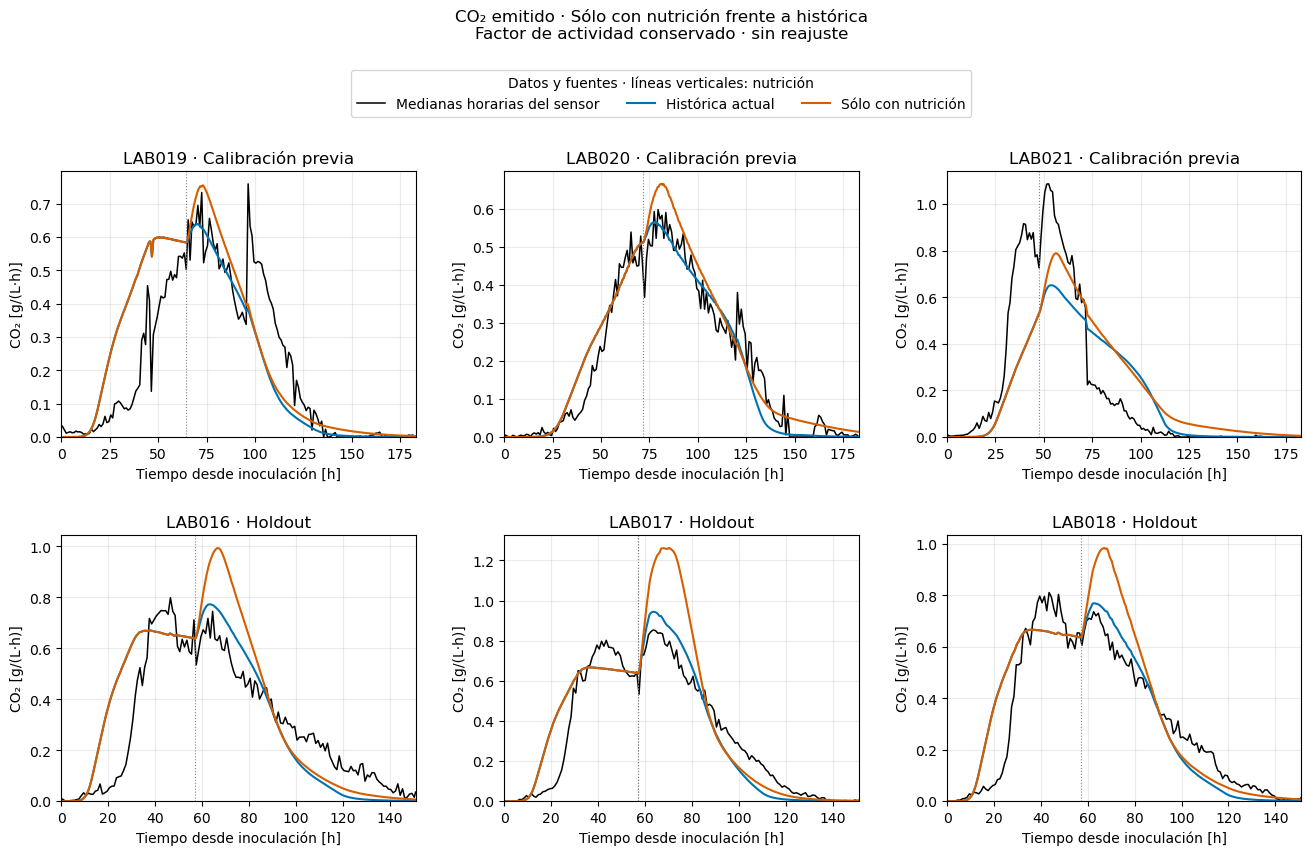

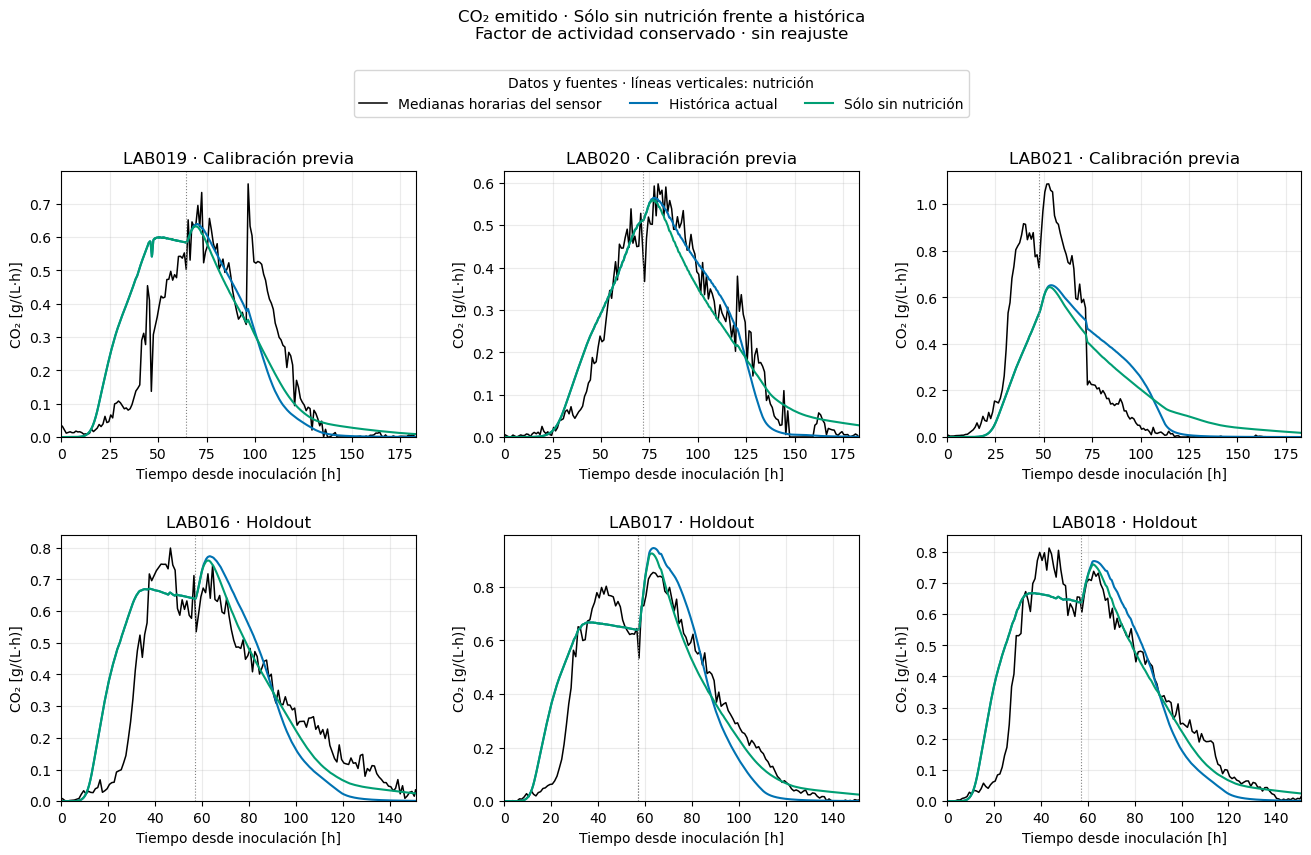

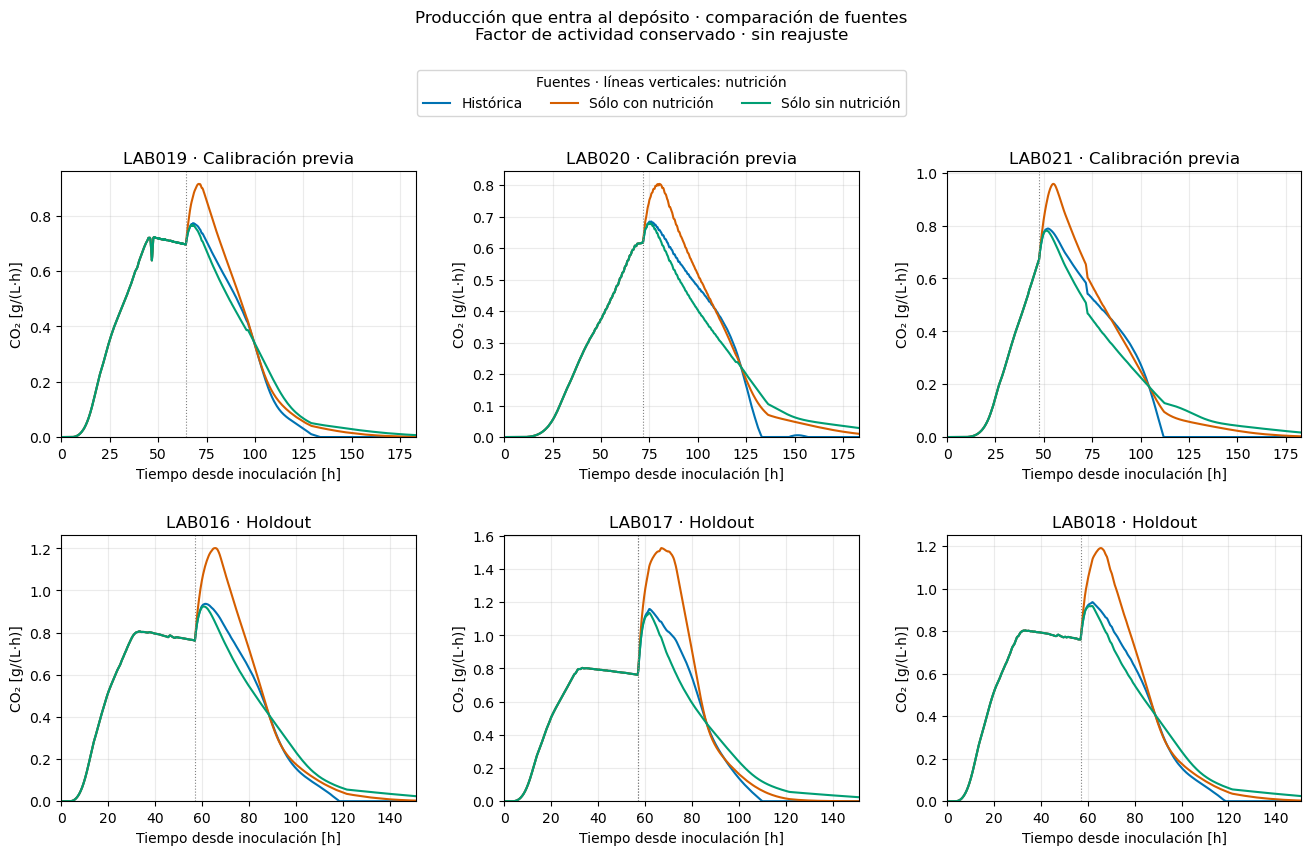

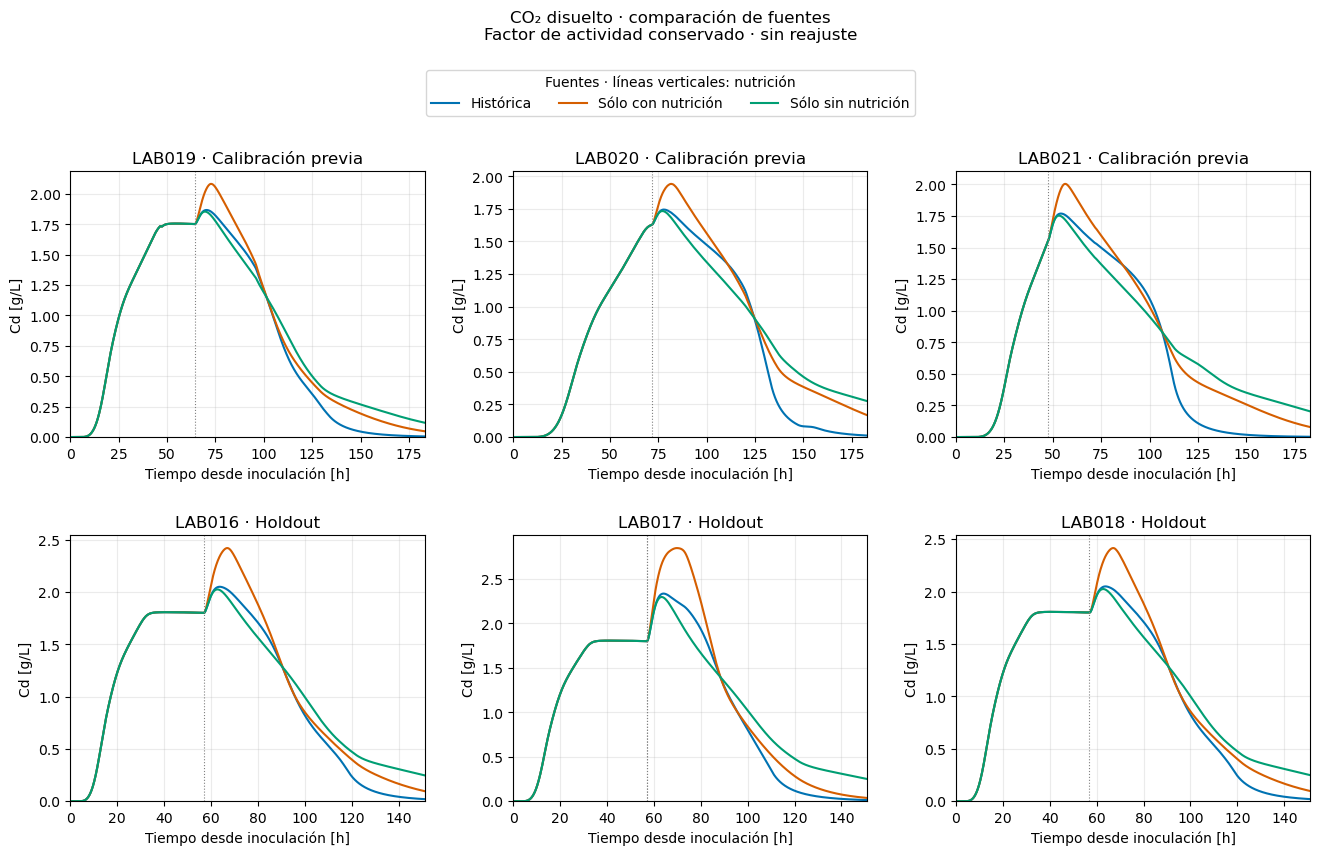

RMSE     bias  area_pred_g_L
role               case                                               
Calibración previa Histórica           0.12706 -0.00514       37.84726
                   Sólo con nutrición  0.12645  0.01661       41.84179
                   Sólo sin nutrición  0.12526 -0.00032       38.71709
Holdout            Histórica           0.12004  0.01107       50.19382
                   Sólo con nutrición  0.16273  0.04839       55.86276
                   Sólo sin nutrición  0.10747  0.01662       51.01315

Verificado: modelos, parámetros, resultados previos y notebooks anteriores intactos. Sin exportar CSV/PNG.


In [3]:
def panels(title):
 fig,axes=plt.subplots(2,3,figsize=(16,9))
 fig.suptitle(title+'\nFactor de actividad conservado · sin reajuste',y=.99)
 fig.subplots_adjust(top=.81,hspace=.37,wspace=.25)
 return fig,axes
for alternative,color in [('Sólo con nutrición','#D55E00'),('Sólo sin nutrición','#009E73')]:
 fig,axes=panels('CO₂ emitido · '+alternative+' frente a histórica')
 for ax,lab in zip(axes.flat,LABS):
  o=observed[lab];old=curves['Histórica',lab];alt=curves[alternative,lab]
  ax.plot(o.time_h,o.co2_raw_g_l_h,color='black',lw=1.1,label='Medianas horarias del sensor')
  ax.plot(old.index,old.qpred,color='#0072B2',label='Histórica actual')
  ax.plot(alt.index,alt.qpred,color=color,label=alternative)
  for ti,d in v.batches[lab].pulses['N']:ax.axvline(ti,color='gray',ls=':',lw=.8)
  role='Calibración previa' if lab in LABS[:3] else 'Holdout'
  ax.set(title=lab+' · '+role,xlabel='Tiempo desde inoculación [h]',ylabel='CO₂ [g/(L·h)]',xlim=(0,old.index[-1]));ax.set_ylim(bottom=0);ax.grid(alpha=.25)
 handles,labels=axes.flat[0].get_legend_handles_labels();fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.93),ncol=3,title='Datos y fuentes · líneas verticales: nutrición')
 plt.show()
for variable,title,ylabel in [('qprod','Producción que entra al depósito','CO₂ [g/(L·h)]'),('Cd','CO₂ disuelto','Cd [g/L]')]:
 fig,axes=panels(title+' · comparación de fuentes')
 for ax,lab in zip(axes.flat,LABS):
  for name,color in [('Histórica','#0072B2'),('Sólo con nutrición','#D55E00'),('Sólo sin nutrición','#009E73')]:
   f=curves[name,lab];ax.plot(f.index,f[variable],label=name,color=color)
  for ti,d in v.batches[lab].pulses['N']:ax.axvline(ti,color='gray',ls=':',lw=.8)
  role='Calibración previa' if lab in LABS[:3] else 'Holdout'
  ax.set(title=lab+' · '+role,xlabel='Tiempo desde inoculación [h]',ylabel=ylabel,xlim=(0,f.index[-1]));ax.set_ylim(bottom=0);ax.grid(alpha=.25)
 handles,labels=axes.flat[0].get_legend_handles_labels();fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.93),ncol=3,title='Fuentes · líneas verticales: nutrición')
 plt.show()
display(metrics.groupby(['role','case'])[['RMSE','bias','area_pred_g_L']].mean().round(5))
assert hashes()==before,'Se modificó un archivo protegido'
print('Verificado: modelos, parámetros, resultados previos y notebooks anteriores intactos. Sin exportar CSV/PNG.')


## Resultado con el factor de actividad conservado

La referencia reproduce exactamente el objetivo histórico guardado: 0.0586968270. Las diferencias anteriores a nutrición son menores que 1.4×10⁻⁷ g/(L·h). Los balances conservan masa y los archivos anteriores permanecen intactos.

Promedio de RMSE por laboratorio [g/(L·h)]:

| Grupo | Histórica | Sólo con nutrición, con a(t) | Sólo sin nutrición, con a(t) |
|---|---:|---:|---:|
| LAB019–021, calibración previa | 0.12706 | 0.12645 | 0.12526 |
| LAB016–018, holdout | 0.12004 | 0.16273 | 0.10747 |

q₀ con el factor conservado mejora los tres laboratorios del holdout: RMSE 0.14268→0.12945 (LAB016), 0.10983→0.09521 (LAB017) y 0.10761→0.09775 (LAB018). En LAB019–021 mejora LAB019 y LAB021 y empeora ligeramente LAB020. La trayectoria nutrida con el factor mejora algo el promedio LAB019–021, pero empeora el holdout.

Esto corrige la interpretación del diagnóstico 05: retirar el factor de actividad junto con la mezcla confundía ambos efectos. Con a(t) conservado, la trayectoria q₀ es competitiva y mejora el RMSE medio de ambos grupos con estos parámetros congelados. No demuestra que debamos suprimir la nutrición química: M, a(t), gate, O₂ y Csat conservan sus definiciones históricas, y algunos aún proceden de las trayectorias originales. La prueba aísla la elección de fuente, no elimina todas las dependencias de una segunda simulación en el modelo completo.
